Number of subjects available at every rate: 68
Subject: 037 | Common available measurements: 316 | Sampled measurements: 1000
Subject: 039 | Common available measurements: 771 | Sampled measurements: 1000
Subject: 041 | Common available measurements: 137 | Sampled measurements: 1000
Subject: 055 | Common available measurements: 388 | Sampled measurements: 1000
Subject: 211 | Common available measurements: 144 | Sampled measurements: 1000
Subject: 212 | Common available measurements: 427 | Sampled measurements: 1000
Subject: 213 | Common available measurements: 524 | Sampled measurements: 1000
Subject: 216 | Common available measurements: 285 | Sampled measurements: 1000
Subject: 218 | Common available measurements: 248 | Sampled measurements: 1000
Subject: 219 | Common available measurements: 228 | Sampled measurements: 1000
Subject: 220 | Common available measurements: 7 | Sampled measurements: 1000
Subject: 221 | Common available measurements: 189 | Sampled measurements: 1000
Subject

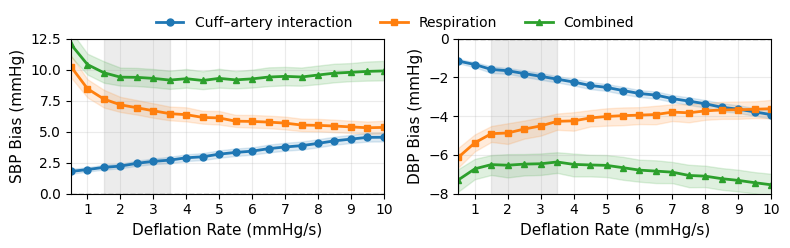

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BP_dir = '../results/simulated_BP'
fig_dir = '../figures'
os.makedirs(fig_dir, exist_ok=True)

n_samples_per_subject = 1000                # Number of measurements sampled per subject at each deflation rate
n_bootstrap = 2000                          # Number of bootstrap samples for confidence intervals
def_rates = np.arange(0.5, 10.01, 0.5)      # Deflation rates to analyze (mmHg/s)
random_seed = 42                            # Random seed for reproducibility

error_columns = [
    'SBP_cuff_error',
    'SBP_resp_error',
    'SBP_combined_error',
    'DBP_cuff_error',
    'DBP_resp_error',
    'DBP_combined_error'
]

bias_names = {
    'SBP_cuff_error': 'SBP_cuff_Bias',
    'SBP_resp_error': 'SBP_resp_Bias',
    'SBP_combined_error': 'SBP_combined_Bias',
    'DBP_cuff_error': 'DBP_cuff_Bias',
    'DBP_resp_error': 'DBP_resp_Bias',
    'DBP_combined_error': 'DBP_combined_Bias'
}

metric_names = list(bias_names.values())


# ============================================================
# Helper functions
# ============================================================
def get_rate_directory(def_rate):
    def_rate_name = f'{def_rate:.1f}'.replace('.', 'p')
    return f'{BP_dir}/{def_rate_name}'


def get_subjects_at_rate(def_rate):
    rate_dir = get_rate_directory(def_rate)
    files = sorted(os.listdir(rate_dir))
    files = [file for file in files if file.endswith('.npz') and file != 'mean_cov.npz']
    return {os.path.splitext(file)[0] for file in files}


def load_subject_errors(def_rate, subject):
    path = f'{get_rate_directory(def_rate)}/{subject}.npz'

    with np.load(path) as data:
        BP = data['BP']
        errors = data['err']

        if errors.shape[0] < 4:
            raise ValueError(f'{path}: expected at least four rows in "err", but found {errors.shape[0]}.')

        if BP.shape[1] != errors.shape[1]:
            raise ValueError(f'{path}: "BP" and "err" have different numbers of measurements.')

        sbp_cuff = np.asarray(errors[0, :], dtype=np.float64)
        dbp_cuff = np.asarray(errors[1, :], dtype=np.float64)
        sbp_resp = np.asarray(errors[2, :], dtype=np.float64)
        dbp_resp = np.asarray(errors[3, :], dtype=np.float64)

    return {
        'SBP_cuff_error': sbp_cuff,
        'SBP_resp_error': sbp_resp,
        'SBP_combined_error': sbp_cuff + sbp_resp,
        'DBP_cuff_error': dbp_cuff,
        'DBP_resp_error': dbp_resp,
        'DBP_combined_error': dbp_cuff + dbp_resp
    }


# ============================================================
# Identify subjects available at every deflation rate
# ============================================================
subject_sets = [get_subjects_at_rate(def_rate) for def_rate in def_rates]
common_subjects = sorted(set.intersection(*subject_sets))

if len(common_subjects) == 0:
    raise RuntimeError('No subjects were found at every deflation rate.')

print(f'Number of subjects available at every rate: {len(common_subjects)}')


# ============================================================
# Determine the common number of measurements for each subject
# ============================================================
# For each subject, indices are restricted to:
#
#     0, 1, ..., minimum_n_measurements - 1
#
# Therefore, every sampled index exists at every deflation rate.
# ============================================================
minimum_measurements = {}

for subject in common_subjects:
    measurement_counts = []

    for def_rate in def_rates:
        path = f'{get_rate_directory(def_rate)}/{subject}.npz'

        with np.load(path) as data:
            n_bp = data['BP'].shape[1]
            n_error = data['err'].shape[1]

        if n_bp != n_error:
            raise ValueError(f'{path}: "BP" and "err" have different numbers of measurements.')

        measurement_counts.append(n_error)

    minimum_measurements[subject] = min(measurement_counts)

    if minimum_measurements[subject] == 0:
        raise ValueError(f'Subject {subject} has no measurements at one or more deflation rates.')


# ============================================================
# Draw the same 100 indices for each subject across all rates
# ============================================================
rng_sampling = np.random.default_rng(random_seed)

sampled_indices = {}

for subject in common_subjects:
    sampled_indices[subject] = rng_sampling.choice(
        minimum_measurements[subject],
        size=n_samples_per_subject,
        replace=True
    )

    print(
        f'Subject: {subject} | '
        f'Common available measurements: {minimum_measurements[subject]} | '
        f'Sampled measurements: {n_samples_per_subject}'
    )


# ============================================================
# Calculate subject-level bias using the fixed samples
# ============================================================
# Each subject contributes one bias value for each error component
# and deflation rate. Consequently, subjects receive equal weight.
# ============================================================
subject_results = []

for def_rate in def_rates:
    print(f'Processing deflation rate: {def_rate:.1f} mmHg/s')

    for subject in common_subjects:
        errors = load_subject_errors(def_rate, subject)
        indices = sampled_indices[subject]

        result = {
            'subject': subject,
            'def_rate': def_rate,
            'n_samples': n_samples_per_subject
        }

        for error_column in error_columns:
            sampled_errors = errors[error_column][indices]

            if not np.all(np.isfinite(sampled_errors)):
                raise ValueError(
                    f'Nonfinite values were found for subject {subject}, '
                    f'rate {def_rate:.1f}, and variable {error_column}.'
                )

            metric_name = bias_names[error_column]
            result[metric_name] = np.mean(sampled_errors)

        subject_results.append(result)


subject_df = pd.DataFrame(subject_results)
subject_df = subject_df.sort_values(['def_rate', 'subject']).reset_index(drop=True)


# ============================================================
# Generate paired subject-level bootstrap samples
# ============================================================
# The same bootstrap subject indices are used at every deflation
# rate and for every error component.
# ============================================================
n_subjects = len(common_subjects)
rng_bootstrap = np.random.default_rng(random_seed + 1)

bootstrap_subject_indices = rng_bootstrap.integers(
    low=0,
    high=n_subjects,
    size=(n_bootstrap, n_subjects)
)


# ============================================================
# Calculate mean subject-level bias and 95% confidence intervals
# ============================================================
summary_results = []

for def_rate in def_rates:
    rate_df = subject_df[subject_df['def_rate'] == def_rate].copy()
    rate_df['subject'] = pd.Categorical(rate_df['subject'], categories=common_subjects, ordered=True)
    rate_df = rate_df.sort_values('subject').reset_index(drop=True)

    result = {
        'def_rate': def_rate,
        'n_subjects': n_subjects,
        'samples_per_subject': n_samples_per_subject,
        'n_sampled_measurements': n_subjects * n_samples_per_subject
    }

    for metric in metric_names:
        subject_values = rate_df[metric].to_numpy(dtype=np.float64)

        # Equal-weight mean across subjects
        result[metric] = np.mean(subject_values)

        # Each row corresponds to one bootstrap sample of subjects
        bootstrap_values = np.mean(subject_values[bootstrap_subject_indices], axis=1)

        result[f'{metric}_lower'] = np.percentile(bootstrap_values, 2.5)
        result[f'{metric}_upper'] = np.percentile(bootstrap_values, 97.5)

    summary_results.append(result)

    print(
        f'Rate: {def_rate:.1f} mmHg/s | '
        f'Subjects: {n_subjects} | '
        f'Samples per subject: {n_samples_per_subject}'
    )


summary_df = pd.DataFrame(summary_results)
summary_df = summary_df.sort_values('def_rate').reset_index(drop=True)

# ============================================================
# Save a compact bias table
# ============================================================
bias_table = summary_df[[
    'def_rate',
    'n_subjects',
    'samples_per_subject',
    'n_sampled_measurements',
    'SBP_cuff_Bias',
    'SBP_resp_Bias',
    'SBP_combined_Bias',
    'DBP_cuff_Bias',
    'DBP_resp_Bias',
    'DBP_combined_Bias'
]].copy()

#%% ============================================================

# Plot settings
FIG_SIZE = (8, 2.5)
XTICK_FONT_SIZE = 10
YTICK_FONT_SIZE = 10
XLABEL_FONT_SIZE = 11
YLABEL_FONT_SIZE = 11
LEGEND_FONT_SIZE = 10

def plot_bias(ax, summary, metric, label, color, marker):
    x = summary['def_rate'].to_numpy()
    y = summary[metric].to_numpy()
    lower = summary[f'{metric}_lower'].to_numpy()
    upper = summary[f'{metric}_upper'].to_numpy()

    ax.plot(x, y, label=label, color=color, marker=marker, linewidth=2, markersize=5)
    ax.fill_between(x, lower, upper, color=color, alpha=0.15)


fig, axes = plt.subplots(nrows=1, ncols=2, figsize=FIG_SIZE, sharex=True)

# SBP panel
plot_bias(axes[0], summary_df, metric='SBP_cuff_Bias', label='Cuff–artery interaction', color='tab:blue', marker='o')
plot_bias(axes[0], summary_df, metric='SBP_resp_Bias', label='Respiration', color='tab:orange', marker='s')
plot_bias(axes[0], summary_df, metric='SBP_combined_Bias', label='Combined', color='tab:green', marker='^')

axes[0].set_xlabel('Deflation Rate (mmHg/s)', fontsize=XLABEL_FONT_SIZE)
axes[0].set_ylabel('SBP Bias (mmHg)', fontsize=YLABEL_FONT_SIZE)
axes[0].set_xlim(0.5, 10.0)
axes[0].set_ylim(0.0, 12.5)

# DBP panel
plot_bias(axes[1], summary_df, metric='DBP_cuff_Bias', label='Cuff–artery interaction', color='tab:blue', marker='o')
plot_bias(axes[1], summary_df, metric='DBP_resp_Bias', label='Respiration', color='tab:orange', marker='s')
plot_bias(axes[1], summary_df, metric='DBP_combined_Bias', label='Combined', color='tab:green', marker='^')

axes[1].set_xlabel('Deflation Rate (mmHg/s)', fontsize=XLABEL_FONT_SIZE)
axes[1].set_ylabel('DBP Bias (mmHg)', fontsize=YLABEL_FONT_SIZE)
axes[1].set_xlim(0.5, 10.0)
axes[1].set_ylim(-8, 0)

# Common formatting
for ax in axes:
    ax.axvspan(1.5, 3.5, color='gray', alpha=0.15, zorder=0)
    ax.axhline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_xticks(np.arange(1, 10.01, 1.0))
    ax.tick_params(axis='x', labelsize=XTICK_FONT_SIZE)
    ax.tick_params(axis='y', labelsize=YTICK_FONT_SIZE)
    ax.grid(alpha=0.25)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=3, fontsize=LEGEND_FONT_SIZE, loc='upper center', bbox_to_anchor=(0.5, 1.0))

fig.tight_layout(rect=[0, 0.0, 1, 0.94])
fig.align_ylabels(axes)

figure_path = f'{fig_dir}/sweep.png'
plt.savefig(figure_path, dpi=300, bbox_inches='tight')
plt.show()